## WELCOME TO PHASE 3: I USED THE PYTHAN STATISTICAL ANLYSIS LIKE LIBRARIES,DESCRIPTIVE STATISTICS,PROBABILITY,CONFIDENCE INTERVEL,HYPOTHESIS TESTING FOR MY PROJECT.

### PROJECT OBJECTIVE:TO ANALYZE THE CLINICAL PARAMETER LIKE DOSAGES,RECOVERY TIME,ASA GRADES,BMI,PAIN SCORE USING ADVANCED DATA SCIENCE WORKFLOW.
### Workflow Steps: Data Loading -> EXPLORE THE DATA -> DESCRIPTIVE STAT -> PROBABILITY -> CONFIDENCE INTERVEL -> HYPOTHESIS TESTING -> VISUALIZE.

## STEP 1 : IMPORT LIBRARIES & LOAD THE DATA:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.weightstats import ztest

## STEP 2: EXPLORE THE DATA:

In [2]:
df = pd.read_csv('cleaned_anesthesia_data.csv')

#print("Final Cleaned Dataset Shape (Rows, Columns):", df.shape)
df.head(5) 1. EXPLORE THE DATA:

### USE HEAD:

In [3]:
df.head(5)

,Patient_ID,Age,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,PreOp_SpO2,...,Surgery_Type_Lap_Cholecystectomy,Surgery_Type_Ortho_Lower_Limb,Surgery_Type_Wound_Debridement,Anesthesia_Type_General,Anesthesia_Type_Local,Anesthesia_Type_Spinal,Surgical_Site_Lower_Abdomen,Surgical_Site_Lower_Limb,Surgical_Site_Upper_Abdomen,Surgical_Site_Upper_Limb
0,PT_0001,49,61.3,164.5,22.7,6,69,115,72,99,...,0,0,0,1,0,0,1,0,0,0
1,PT_0002,37,83.5,168.3,29.5,10,99,140,78,96,...,0,0,0,1,0,0,1,0,0,0
2,PT_0003,41,83.5,159.4,32.9,6,62,120,90,99,...,0,0,0,0,0,1,1,0,0,0
3,PT_0004,64,67.6,177.2,21.5,6,81,160,85,96,...,0,0,0,1,0,0,0,0,0,0
4,PT_0005,65,46.0,157.3,18.6,10,93,126,68,96,...,0,0,0,1,0,0,0,0,0,0


## USE DESCRIBE:

In [4]:
df.describe()

,Age,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,PreOp_SpO2,ASA_Grade,...,Surgery_Type_Lap_Cholecystectomy,Surgery_Type_Ortho_Lower_Limb,Surgery_Type_Wound_Debridement,Anesthesia_Type_General,Anesthesia_Type_Local,Anesthesia_Type_Spinal,Surgical_Site_Lower_Abdomen,Surgical_Site_Lower_Limb,Surgical_Site_Upper_Abdomen,Surgical_Site_Upper_Limb
count,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000,1010.0,...,1010.0,1010.0,1010.0,1010.000000,1010.0,1010.000000,1010.000000,1010.0,1010.0,1010.0
mean,49.511881,66.048750,164.168713,24.613812,8.832673,80.479208,131.716832,79.772277,96.995050,0.0,...,0.0,0.0,0.0,0.668317,0.0,0.284158,0.427723,0.0,0.0,0.0
std,17.673068,11.375006,7.881732,4.877419,2.060705,11.913467,17.232308,9.341003,1.391955,0.0,...,0.0,0.0,0.0,0.471051,0.0,0.451236,0.494994,0.0,0.0,0.0
min,18.000000,34.737500,142.900000,12.600000,5.000000,60.000000,102.000000,64.000000,95.000000,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0
25%,34.000000,58.100000,158.800000,21.200000,8.000000,70.250000,116.000000,72.000000,96.000000,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0
50%,50.000000,66.000000,164.200000,24.300000,10.000000,81.000000,132.000000,80.000000,97.000000,0.0,...,0.0,0.0,0.0,1.000000,0.0,0.000000,0.000000,0.0,0.0,0.0
75%,65.000000,73.675000,169.400000,27.900000,10.000000,90.000000,147.000000,88.000000,98.000000,0.0,...,0.0,0.0,0.0,1.000000,0.0,1.000000,1.000000,0.0,0.0,0.0
max,79.000000,97.037500,185.300000,37.950000,12.000000,101.000000,161.000000,95.000000,99.000000,0.0,...,0.0,0.0,0.0,1.000000,0.0,1.000000,1.000000,0.0,0.0,0.0


## STEP 3: DESCRIPTIVE STATISTCS:

### 1. USE SELECT DESCRIBE:

In [5]:
df[['PACU_Recovery_Time_mins', 'Age', 'BMI', 'Weight_kg', 'Bupivacaine_Dose_mg']].describe()

,PACU_Recovery_Time_mins,Age,BMI,Weight_kg,Bupivacaine_Dose_mg
count,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000
mean,40.647797,49.511881,24.613812,66.048750,3.760099
std,11.389026,17.673068,4.877419,11.375006,5.642278
min,11.700000,18.000000,12.600000,34.737500,0.000000
25%,31.825000,34.000000,21.200000,58.100000,0.000000
50%,40.600000,50.000000,24.300000,66.000000,0.000000
75%,48.700000,65.000000,27.900000,73.675000,11.100000
max,74.012500,79.000000,37.950000,97.037500,16.000000


### 1. USE MIN:

In [6]:
cols = ['PACU_Recovery_Time_mins', 'Age', 'BMI', 'Weight_kg', 'Bupivacaine_Dose_mg']
data_range = df[cols].max() - df[cols].min()
print("--- RANGE ---")
print(data_range)

--- RANGE ---
PACU_Recovery_Time_mins    62.3125
Age                        61.0000
BMI                        25.3500
Weight_kg                  62.3000
Bupivacaine_Dose_mg        16.0000
dtype: float64


### 2. USE MAX:

In [7]:
df[['PACU_Recovery_Time_mins', 'Age', 'BMI', 'Weight_kg', 'Bupivacaine_Dose_mg']].max()

PACU_Recovery_Time_mins    74.0125
Age                        79.0000
BMI                        37.9500
Weight_kg                  97.0375
Bupivacaine_Dose_mg        16.0000
dtype: float64

### 3. USE MEAN:

In [8]:
df[['PACU_Recovery_Time_mins', 'Age', 'BMI', 'Weight_kg', 'Bupivacaine_Dose_mg']].mean()

PACU_Recovery_Time_mins    40.647797
Age                        49.511881
BMI                        24.613812
Weight_kg                  66.048750
Bupivacaine_Dose_mg         3.760099
dtype: float64

### 4. USE MEDIAN:

In [9]:
df[['PACU_Recovery_Time_mins', 'Age', 'BMI', 'Weight_kg', 'Bupivacaine_Dose_mg']].median()

PACU_Recovery_Time_mins    40.6
Age                        50.0
BMI                        24.3
Weight_kg                  66.0
Bupivacaine_Dose_mg         0.0
dtype: float64

### 5. USE MODE:

In [10]:
df[['PACU_Recovery_Time_mins', 'Age', 'BMI', 'Weight_kg', 'Bupivacaine_Dose_mg']].mode()

,PACU_Recovery_Time_mins,Age,BMI,Weight_kg,Bupivacaine_Dose_mg
0,40.6,50,24.3,66.0,0.0


### 6. USE STD:

In [11]:
df[['PACU_Recovery_Time_mins', 'Age', 'BMI', 'Weight_kg', 'Bupivacaine_Dose_mg']].std()

PACU_Recovery_Time_mins    11.389026
Age                        17.673068
BMI                         4.877419
Weight_kg                  11.375006
Bupivacaine_Dose_mg         5.642278
dtype: float64

### 7. USE RANGE:

In [12]:
column = ['PACU_Recovery_Time_mins', 'Age', 'BMI', 'Weight_kg', 'Bupivacaine_Dose_mg']
data_range = df[column].max() - df[column].min()
print("--- RANGE ---")
print(data_range)

--- RANGE ---
PACU_Recovery_Time_mins    62.3125
Age                        61.0000
BMI                        25.3500
Weight_kg                  62.3000
Bupivacaine_Dose_mg        16.0000
dtype: float64


### 8. USE QUARTILES:

In [13]:
print("--- QUARTILES (25%, 50%, 75%) ---")
print(df[column].quantile([0.25, 0.5, 0.75]))

--- QUARTILES (25%, 50%, 75%) ---
      PACU_Recovery_Time_mins   Age   BMI  Weight_kg  Bupivacaine_Dose_mg
0.25                   31.825  34.0  21.2     58.100                  0.0
0.50                   40.600  50.0  24.3     66.000                  0.0
0.75                   48.700  65.0  27.9     73.675                 11.1


### 9. Five-Number Summary:

In [21]:
df[column].describe()

,PACU_Recovery_Time_mins,Age,BMI,Weight_kg,Bupivacaine_Dose_mg
count,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000
mean,40.647797,49.511881,24.613812,66.048750,3.760099
std,11.389026,17.673068,4.877419,11.375006,5.642278
min,11.700000,18.000000,12.600000,34.737500,0.000000
25%,31.825000,34.000000,21.200000,58.100000,0.000000
50%,40.600000,50.000000,24.300000,66.000000,0.000000
75%,48.700000,65.000000,27.900000,73.675000,11.100000
max,74.012500,79.000000,37.950000,97.037500,16.000000


### 10. RESULT DESC STAT VISUALIZATION:

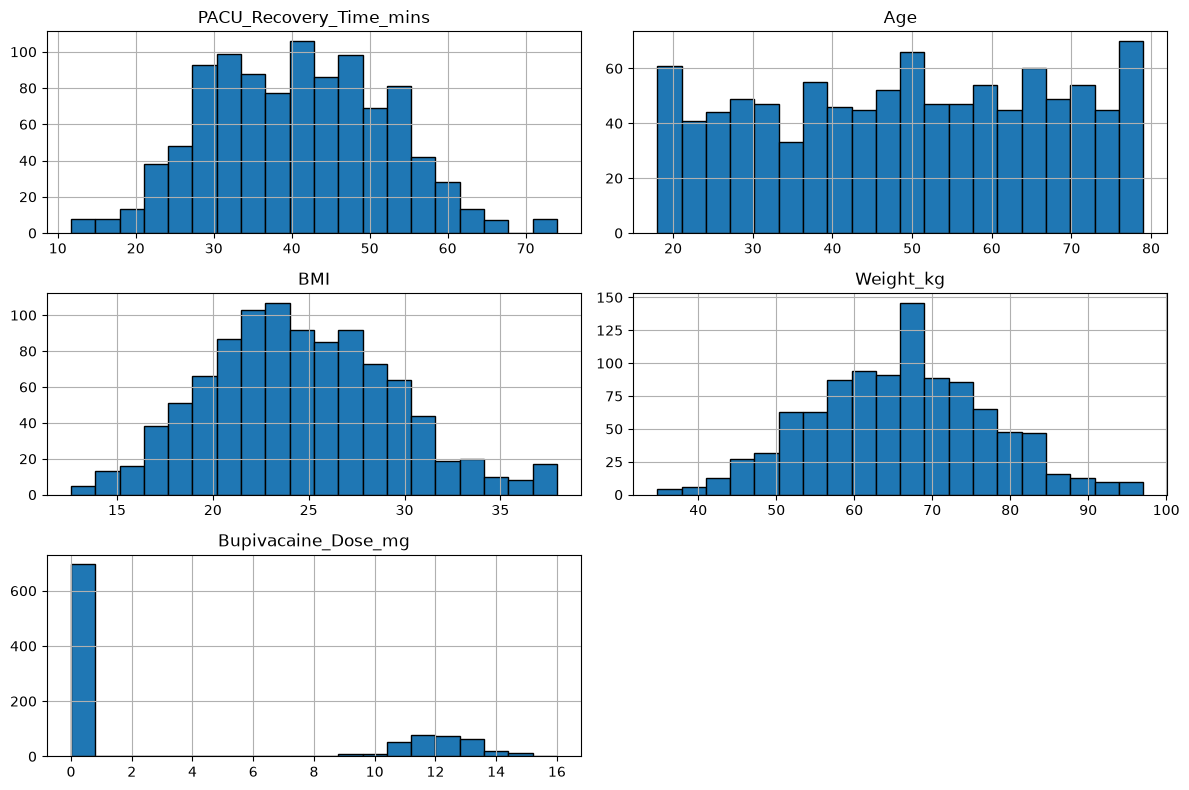

In [22]:
df[column].hist(bins=20, figsize=(12, 8), edgecolor='black')
plt.tight_layout()
plt.show()

### 11. RESULT OUTLIER STAT VISUALIZATION:

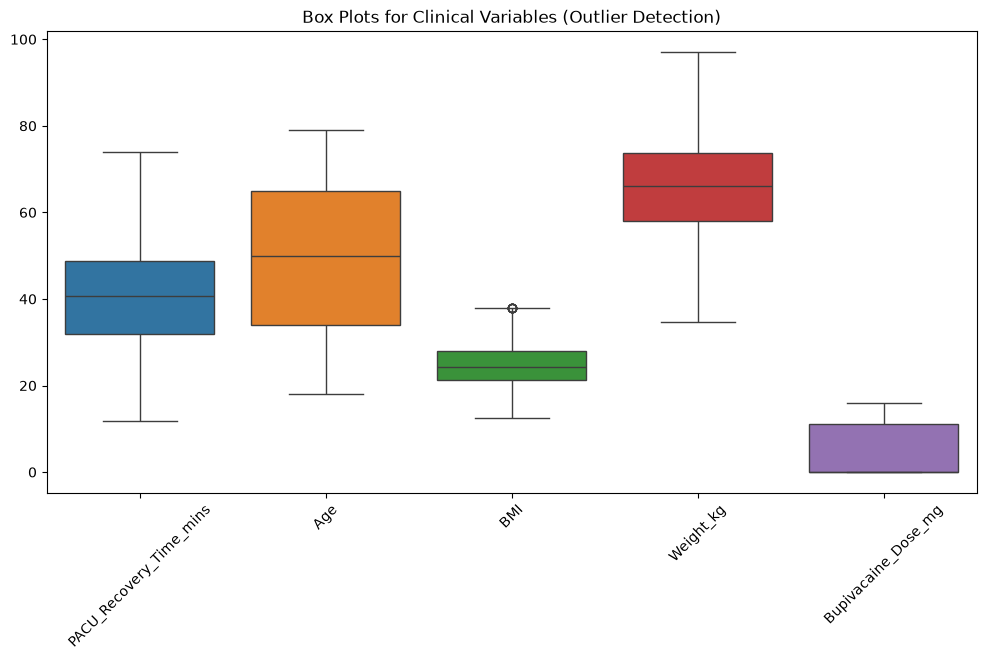

In [16]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[column])
plt.title('Box Plots for Clinical Variables (Outlier Detection)')
plt.xticks(rotation=45)
plt.show()

## STEP2 : PROBABILITY:

In [17]:
df['Rescue_Vasopressor_Used'] = df['Rescue_Vasopressor_Used'].fillna('No')
print(df['Rescue_Vasopressor_Used'].value_counts())

Rescue_Vasopressor_Used
No               792
Ephedrine        110
Phenylephrine    108
Name: count, dtype: int64


### 1.  USE NORMAL DES & ZSCORE:

In [18]:
column = ['PACU_Recovery_Time_mins', 'Age', 'BMI', 'Weight_kg', 'Bupivacaine_Dose_mg']

In [19]:
for col in column:
    df[col + '_zscore'] = stats.zscore(df[col], nan_policy='omit')
    df[col + '_gt'] = 1 - stats.norm.cdf(df[col + '_zscore'])
    df[col + '_lt'] = stats.norm.cdf(df[col + '_zscore'])

In [23]:
p_rescue = (df['Rescue_Vasopressor_Used'] != 'No').mean()

In [24]:
df.head(5)

,Patient_ID,Age,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,PreOp_SpO2,...,Age_lt,BMI_zscore,BMI_gt,BMI_lt,Weight_kg_zscore,Weight_kg_gt,Weight_kg_lt,Bupivacaine_Dose_mg_zscore,Bupivacaine_Dose_mg_gt,Bupivacaine_Dose_mg_lt
0,PT_0001,49,61.3,164.5,22.7,6,69,115,72,99,...,0.488441,-0.392577,0.652684,0.347316,-0.417679,0.661909,0.338091,-0.666745,0.747533,0.252467
1,PT_0002,37,83.5,168.3,29.5,10,99,140,78,96,...,0.239375,1.002294,0.158101,0.841899,1.534935,0.062400,0.937600,-0.666745,0.747533,0.252467
2,PT_0003,41,83.5,159.4,32.9,6,62,120,90,99,...,0.314950,1.699730,0.044591,0.955409,1.534935,0.062400,0.937600,1.354716,0.087754,0.912246
3,PT_0004,64,67.6,177.2,21.5,6,81,160,85,96,...,0.793946,-0.638730,0.738501,0.261499,0.136441,0.445736,0.554264,-0.666745,0.747533,0.252467
4,PT_0005,65,46.0,157.3,18.6,10,93,126,68,96,...,0.809703,-1.233602,0.891324,0.108676,-1.763400,0.961083,0.038917,-0.666745,0.747533,0.252467


### 2. ZSCORE VISUALIZATION:

In [ ]:
for col in column:
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

### 3. USE BINOMINAL PROBA:

In [ ]:
p_rescue = (df['Rescue_Vasopressor_Used'] != 'No').mean()
binom_prob = stats.binom.pmf(3, 10, p_rescue)
print(binom_prob)

### 4. USE POISSON PROBA:

In [ ]:
mean_bupi = df['Bupivacaine_Dose_mg'].mean()
poisson_prob = stats.poisson.pmf(5, mean_bupi)
print(poisson_prob)

### 5. FINAL RESULT:

In [ ]:
df.head(5)

### 5. RESULT PROBA VISUALIZATION:

In [ ]:
for col in column:
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

## STEP 3: CONFIDENCE-INTERVEL:

### 1. USE SAMPLE FOR RECOVERT TIME:

In [ ]:
sample = df.sample(n=50, random_state=42)
stats.norm.interval(0.95, sample["PACU_Recovery_Time_mins"].mean(), stats.sem(sample["PACU_Recovery_Time_mins"], nan_policy='omit'))

### 2. CI RESULT VISUALIZATION:

In [ ]:
sns.pointplot(data=sample, y='PACU_Recovery_Time_mins', errorbar=('ci', 95))
plt.show()

### 3. USE SAMPLE FOR BUPIVACAINE DOSE:

In [ ]:
sample = df.sample(n=50, random_state=42)
stats.norm.interval(0.95, sample["Bupivacaine_Dose_mg"].mean(), stats.sem(sample["sns.pointplot(data=sample, y='PACU_Recovery_Time_mins', errorbar=('ci', 95))
plt.show()"], nan_policy='omit'))

### 4. CI RESULT VISUALIZATION:

In [ ]:
sns.pointplot(data=sample, y='Bupivacaine_Dose_mg', errorbar=('ci', 95))
plt.show()

##  STEP 4: HYPOTHESIS TESTING:

### 1. ANESTHESIA_TYPE VS PACU_RECOVERY_TIME_MINS:

In [ ]:
group_spinal = df[df['Anesthesia_Type'] == 'Spinal']['PACU_Recovery_Time_mins'].dropna()
group_general = df[df['Anesthesia_Type'] == 'General']['PACU_Recovery_Time_mins'].dropna()

stats.ttest_ind(group_spinal, group_general)

### 2. ANESTHESIA_TYPE VS POSTOP_PAIN_SCORE_VAS:

In [ ]:
pain_spinal = df[df['Anesthesia_Type'] == 'Spinal']['PostOp_Pain_Score_VAS'].dropna()
pain_general = df[df['Anesthesia_Type'] == 'General']['PostOp_Pain_Score_VAS'].dropna()

stats.ttest_ind(pain_spinal, pain_general)

### 3. GA_INDUCTION_AGENT VS PACU_RECOVERY_TIME_MINS:

In [ ]:
ind_1 = df[df['GA_Induction_Agent'] == 'Propofol']['PACU_Recovery_Time_mins'].dropna()
ind_2 = df[df['GA_Induction_Agent'] == 'Etomidate']['PACU_Recovery_Time_mins'].dropna()

stats.ttest_ind(ind_1, ind_2)

### 4. SPINAL_ADJUVANT_FENTANYL_MCG VS POSTOP_PAIN_SCORE_VAS:

In [ ]:
with_fentanyl = df[df['Spinal_Adjuvant_Fentanyl_mcg'] > 0]['PostOp_Pain_Score_VAS'].dropna()
no_fentanyl = df[df['Spinal_Adjuvant_Fentanyl_mcg'] == 0]['PostOp_Pain_Score_VAS'].dropna()

stats.ttest_ind(with_fentanyl, no_fentanyl)

### 5. PREV_ANAESTHESIA_COMPLICATION VS PACU_RECOVERY_TIME_MINS:

In [ ]:
comp_yes = df[df['Prev_Anesthesia_Complication'] == 'Yes']['PACU_Recovery_Time_mins'].dropna()
comp_no = df[df['Prev_Anesthesia_Complication'] == 'No']['PACU_Recovery_Time_mins'].dropna()

stats.ttest_ind(comp_yes, comp_no)

### 6. RESULT VISUALIZATION:

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Anesthesia Type vs PACU Recovery Time
sns.boxplot(data=df, x='Anesthesia_Type', y='PACU_Recovery_Time_mins', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('1. PACU Recovery Time by Anesthesia Type')

# 2. Anesthesia Type vs Post-Op Pain Score (VAS)
sns.boxplot(data=df, x='Anesthesia_Type', y='PostOp_Pain_Score_VAS', ax=axes[0, 1], palette='Set1')
axes[0, 1].set_title('2. Post-Op Pain Score by Anesthesia Type')

# 3. Fentanyl Adjuvant vs Post-Op Pain Score
sns.barplot(data=df, x=(df['Spinal_Adjuvant_Fentanyl_mcg'] > 0), y='PostOp_Pain_Score_VAS', ax=axes[1, 0], palette='coolwarm')
axes[1, 0].set_title('3. Pain Score: Without Fentanyl (False) vs With Fentanyl (True)')

# 4. Anesthesia Type vs PONV (Nausea/Vomiting) Count
sns.countplot(data=df, x='Anesthesia_Type', hue='PONV_Occurred', ax=axes[1, 1], palette='viridis')
axes[1, 1].set_title('4. Post-Op Nausea/Vomiting (PONV) by Anesthesia Type')

plt.tight_layout()
plt.show()

## STEP 5.  FINAL ANALYSIS & STATISTICAL OVERVIEW:
**PROCESS SUMMARY: **ALL PREPROCESSING STEPS INCLUDING DISCRIPTIVE STAT,PROBABILITY,CONFIDENCE INTERVEL,HYPOTHESIS TESTING HAVE BEEN SUCCESSFULLY COMPLETED.
**FINAL RESULT: **THE DATASET IS NOW CLEAN, ROBUST, AND FULLY OPTIMIZED FOR ADVANCED STATISTICAL DATA MODELING AND PRE-MACHINE LEARNING WORKFLOWS.

## STEP 6: FINAL DATASET:

In [25]:
print("Final Cleaned Dataset Shape (Rows, Columns):", df.shape)
df.head(5)

Final Cleaned Dataset Shape (Rows, Columns): (1010, 77)


,Patient_ID,Age,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,PreOp_SpO2,...,Age_lt,BMI_zscore,BMI_gt,BMI_lt,Weight_kg_zscore,Weight_kg_gt,Weight_kg_lt,Bupivacaine_Dose_mg_zscore,Bupivacaine_Dose_mg_gt,Bupivacaine_Dose_mg_lt
0,PT_0001,49,61.3,164.5,22.7,6,69,115,72,99,...,0.488441,-0.392577,0.652684,0.347316,-0.417679,0.661909,0.338091,-0.666745,0.747533,0.252467
1,PT_0002,37,83.5,168.3,29.5,10,99,140,78,96,...,0.239375,1.002294,0.158101,0.841899,1.534935,0.062400,0.937600,-0.666745,0.747533,0.252467
2,PT_0003,41,83.5,159.4,32.9,6,62,120,90,99,...,0.314950,1.699730,0.044591,0.955409,1.534935,0.062400,0.937600,1.354716,0.087754,0.912246
3,PT_0004,64,67.6,177.2,21.5,6,81,160,85,96,...,0.793946,-0.638730,0.738501,0.261499,0.136441,0.445736,0.554264,-0.666745,0.747533,0.252467
4,PT_0005,65,46.0,157.3,18.6,10,93,126,68,96,...,0.809703,-1.233602,0.891324,0.108676,-1.763400,0.961083,0.038917,-0.666745,0.747533,0.252467
